In [1]:
#librerias
import pandas as pd
import numpy as np  # matrices y vectores
import matplotlib.pyplot as plt #gráfica

import warnings
warnings.simplefilter("ignore")

In [2]:
#cargar datos preparados
data = pd.read_csv("hotel_bookings_preparado.csv")
data.head()

,hotel,is_canceled,lead_time,arrival_date_month,adults,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,July,2,PRT,Direct,Direct,0,0,0,C,3,No Deposit,0,Transient,0,0
1,Resort Hotel,0,737,July,2,PRT,Direct,Direct,0,0,0,C,4,No Deposit,0,Transient,0,0
2,Resort Hotel,0,7,July,1,GBR,Direct,Direct,0,0,0,A,0,No Deposit,0,Transient,0,0
3,Resort Hotel,0,13,July,1,GBR,Corporate,Corporate,0,0,0,A,0,No Deposit,0,Transient,0,0
4,Resort Hotel,0,14,July,2,GBR,Online TA,TA/TO,0,0,0,A,0,No Deposit,0,Transient,0,1


In [3]:

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119210 entries, 0 to 119209
Data columns (total 18 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   hotel                           119210 non-null  object
 1   is_canceled                     119210 non-null  int64 
 2   lead_time                       119210 non-null  int64 
 3   arrival_date_month              119210 non-null  object
 4   adults                          119210 non-null  int64 
 5   country                         119210 non-null  object
 6   market_segment                  119210 non-null  object
 7   distribution_channel            119210 non-null  object
 8   is_repeated_guest               119210 non-null  int64 
 9   previous_cancellations          119210 non-null  int64 
 10  previous_bookings_not_canceled  119210 non-null  int64 
 11  reserved_room_type              119210 non-null  object
 12  booking_changes               

In [4]:
#Configuración de variables
objetivo = 'is_canceled'
predictoras_numericas = ['lead_time', 'adults', 'previous_cancellations', 'previous_bookings_not_canceled',
                         'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests']
predictoras_categoricas_2cat = ['hotel', 'is_repeated_guest']
predictoras_categoricas_multicat = ['arrival_date_month', 'country', 'market_segment', 'distribution_channel',
                                    'reserved_room_type', 'deposit_type', 'customer_type']

In [5]:
#Corrección de tipos de datos
for variable in predictoras_categoricas_2cat + predictoras_categoricas_multicat:
    data[variable] = data[variable].astype(str).astype('category')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119210 entries, 0 to 119209
Data columns (total 18 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   hotel                           119210 non-null  category
 1   is_canceled                     119210 non-null  int64   
 2   lead_time                       119210 non-null  int64   
 3   arrival_date_month              119210 non-null  category
 4   adults                          119210 non-null  int64   
 5   country                         119210 non-null  category
 6   market_segment                  119210 non-null  category
 7   distribution_channel            119210 non-null  category
 8   is_repeated_guest               119210 non-null  category
 9   previous_cancellations          119210 non-null  int64   
 10  previous_bookings_not_canceled  119210 non-null  int64   
 11  reserved_room_type              119210 non-null  category
 12  bo

<Axes: xlabel='is_canceled'>

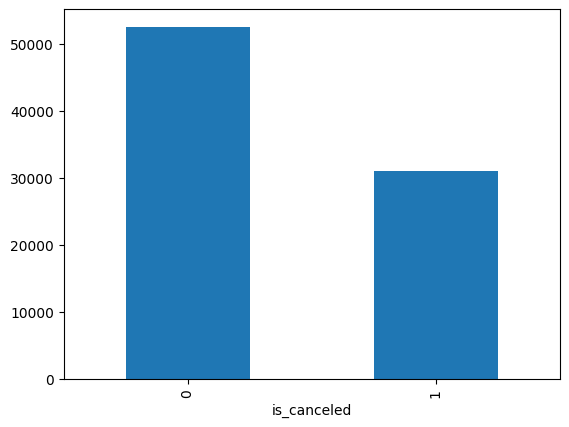

In [6]:
#División 70-30
from sklearn.model_selection import train_test_split
X = data.drop(objetivo, axis = 1) # Variables predictoras
Y = data[objetivo] #Variable objetivo
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42) #Muestreo estratificado
Y_train.value_counts().plot(kind='bar')

In [7]:
#Creación de variables: los países con menos del 0.5% de las reservas del 70% (antes del balanceo) se agrupan en "Otros"
frecuencia = X_train['country'].value_counts(normalize=True)
paises = list(frecuencia[frecuencia >= 0.005].index)
print("Países que se conservan:", len(paises))

X_train['country'] = X_train['country'].astype(str).where(X_train['country'].astype(str).isin(paises), 'Otros').astype('category')
X_train['country'].value_counts()

Países que se conservan: 20


country
PRT      34339
GBR       8460
FRA       7308
ESP       5936
DEU       5083
Otros     4811
ITA       2581
IRL       2357
BEL       1653
BRA       1549
NLD       1503
USA       1456
CHE       1206
AUT        880
CN         877
CHN        720
SWE        720
POL        646
ISR        482
RUS        451
NOR        429
Name: count, dtype: int64

<Axes: xlabel='is_canceled'>

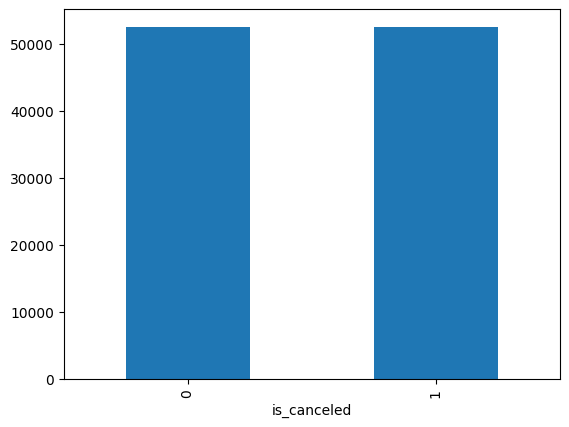

In [8]:
#Balanceo de datos: SOLO el 70%
from imblearn.over_sampling import SMOTENC

categoricas = predictoras_categoricas_2cat + predictoras_categoricas_multicat
posiciones = [X_train.columns.get_loc(variable) for variable in categoricas]

smote = SMOTENC(categorical_features=posiciones, random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, Y_train)

#  dataframe con los resultados (X_smote, y_smote)
data_train = pd.DataFrame(columns=X_smote.columns.values, data=X_smote)
data_train[objetivo] = y_smote.values
data_train[objetivo].value_counts().plot(kind='bar')

In [9]:
#Dummies para las variables predictoras
data_train = pd.get_dummies(data_train, columns=predictoras_categoricas_multicat, drop_first=False, dtype=int) #3 o más categorías
data_train = pd.get_dummies(data_train, columns=predictoras_categoricas_2cat, drop_first=True, dtype=int) #2 categorías
data_train.head()

,lead_time,adults,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,is_canceled,arrival_date_month_April,...,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1
0,53,2,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,1,0,1,0
1,211,1,0,0,0,0,0,0,1,0,...,0,1,0,0,0,0,1,0,0,0
2,8,1,1,16,2,0,1,2,0,0,...,0,1,0,0,0,0,1,0,0,1
3,23,1,0,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,105,2,0,0,0,0,0,0,1,1,...,0,0,1,0,0,0,1,0,0,0


In [10]:
#Se separa variables predictoras y objetivo
X = data_train.drop(objetivo, axis = 1)
Y = data_train[objetivo]
X.shape

(105016, 70)

In [11]:
#Normalizacion las variables numéricas
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler()
min_max_scaler.fit(X[predictoras_numericas]) #Ajuste de los parametros: max - min
X[predictoras_numericas] = min_max_scaler.transform(X[predictoras_numericas]) #70%
X.head()

,lead_time,adults,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,arrival_date_month_April,arrival_date_month_August,...,reserved_room_type_L,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,hotel_Resort Hotel,is_repeated_guest_1
0,0.071913,0.2,0.000000,0.000000,0.000000,0.0,0.000000,0.2,0,0,...,0,1,0,0,0,0,1,0,1,0
1,0.286296,0.1,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0,0,...,0,1,0,0,0,0,1,0,0,0
2,0.010855,0.1,0.038462,0.231884,0.111111,0.0,0.333333,0.4,0,0,...,0,1,0,0,0,0,1,0,0,1
3,0.031208,0.1,0.000000,0.000000,0.055556,0.0,0.000000,0.0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,0.142469,0.2,0.000000,0.000000,0.000000,0.0,0.000000,0.0,1,0,...,0,0,1,0,0,0,1,0,0,0


In [12]:
#Validación Cruzada
from sklearn.model_selection import cross_validate, StratifiedKFold

#Dataframe para comparar los modelos
comparacion_CV = pd.DataFrame()
#Dataframe con los promedios de las medidas de calidad
medidas_CV = pd.DataFrame()
scoring = ('f1_macro', 'accuracy', 'precision_macro', 'recall_macro')
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42) #Muestreo estratificado

In [13]:
#Tree
from sklearn import tree
modelTree = tree.DecisionTreeClassifier(criterion='gini', min_samples_leaf=20, max_depth=15, random_state=42)

scores = cross_validate(modelTree, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

fit_time                 0.422482
score_time               0.014399
test_f1_macro            0.858745
train_f1_macro           0.866154
test_accuracy            0.858860
train_accuracy           0.866264
test_precision_macro     0.860044
train_precision_macro    0.867465
test_recall_macro        0.858860
train_recall_macro       0.866264
dtype: float64

In [14]:
#Se almacena en el df la medida a comparar
comparacion_CV['Tree'] = scores['test_f1_macro']
medidas_CV['Tree'] = scores.mean()

In [15]:
#Método Perezoso
from sklearn.neighbors import KNeighborsClassifier
model_knn = KNeighborsClassifier(n_neighbors=11, metric='euclidean')

scores = cross_validate(model_knn, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

  File "c:\python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


fit_time                 0.053488
score_time               2.426946
test_f1_macro            0.842418
train_f1_macro           0.869184
test_accuracy            0.842738
train_accuracy           0.869406
test_precision_macro     0.845554
train_precision_macro    0.871936
test_recall_macro        0.842738
train_recall_macro       0.869406
dtype: float64

In [16]:
comparacion_CV['Knn'] = scores['test_f1_macro']
medidas_CV['Knn'] = scores.mean()

In [17]:
#Red neuronal
from sklearn.neural_network import MLPClassifier
model_rn = MLPClassifier(activation="relu", hidden_layer_sizes=(50), learning_rate='constant',
                         learning_rate_init=0.01, momentum=0.3, max_iter=500, early_stopping=True, random_state=42)

scores = cross_validate(model_rn, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

fit_time                 11.458129
score_time                0.017787
test_f1_macro             0.867901
train_f1_macro            0.878046
test_accuracy             0.868030
train_accuracy            0.878164
test_precision_macro      0.869460
train_precision_macro     0.879636
test_recall_macro         0.868029
train_recall_macro        0.878164
dtype: float64

In [18]:
comparacion_CV['NN'] = scores['test_f1_macro']
medidas_CV['NN'] = scores.mean()

In [19]:
#SVM
from sklearn.svm import SVC
model_svm = SVC(kernel='rbf', C=1, random_state=42)

scores = cross_validate(model_svm, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

fit_time                 295.227757
score_time                30.552948
test_f1_macro              0.858488
train_f1_macro             0.864403
test_accuracy              0.858964
train_accuracy             0.864844
test_precision_macro       0.863858
train_precision_macro      0.869654
test_recall_macro          0.858964
train_recall_macro         0.864844
dtype: float64

In [20]:
comparacion_CV['SVM'] = scores['test_f1_macro']
medidas_CV['SVM'] = scores.mean()

In [21]:
#Random Forest (ensamble)
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier(n_estimators=200, max_samples=0.9, criterion='gini',
                                  max_depth=20, min_samples_leaf=2, random_state=42, n_jobs=-1)

scores = cross_validate(model_rf, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

fit_time                 4.683516
score_time               0.093936
test_f1_macro            0.874938
train_f1_macro           0.884181
test_accuracy            0.875219
train_accuracy           0.884425
test_precision_macro     0.878616
train_precision_macro    0.887689
test_recall_macro        0.875219
train_recall_macro       0.884425
dtype: float64

In [22]:
comparacion_CV['RF'] = scores['test_f1_macro']
medidas_CV['RF'] = scores.mean()

In [23]:
#XGBoost (ensamble)
from xgboost import XGBClassifier
model_xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)

scores = cross_validate(model_xgb, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

fit_time                 1.277334
score_time               0.045220
test_f1_macro            0.877068
train_f1_macro           0.886392
test_accuracy            0.877162
train_accuracy           0.886476
test_precision_macro     0.878317
train_precision_macro    0.887614
test_recall_macro        0.877162
train_recall_macro       0.886476
dtype: float64

In [24]:
comparacion_CV['XGBoost'] = scores['test_f1_macro']
medidas_CV['XGBoost'] = scores.mean()

In [25]:
#Gradient Boosting (ensamble)
from sklearn.ensemble import GradientBoostingClassifier
model_gb = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42)

scores = cross_validate(model_gb, X, Y, cv=cv, scoring=scoring, return_train_score=True)
scores = pd.DataFrame(scores)
scores.mean()

fit_time                 27.203710
score_time                0.043526
test_f1_macro             0.867138
train_f1_macro            0.869556
test_accuracy             0.867268
train_accuracy            0.869678
test_precision_macro      0.868706
train_precision_macro     0.871073
test_recall_macro         0.867268
train_recall_macro        0.869678
dtype: float64

In [26]:
comparacion_CV['GB'] = scores['test_f1_macro']
medidas_CV['GB'] = scores.mean()

In [27]:
#Tabla de medidas de calidad de los 7 modelos
medidas_CV.T[['test_f1_macro', 'test_accuracy', 'test_precision_macro', 'test_recall_macro', 'fit_time']].sort_values('test_f1_macro', ascending=False).round(4)

,test_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,fit_time
XGBoost,0.8771,0.8772,0.8783,0.8772,1.2773
RF,0.8749,0.8752,0.8786,0.8752,4.6835
NN,0.8679,0.8680,0.8695,0.8680,11.4581
GB,0.8671,0.8673,0.8687,0.8673,27.2037
Tree,0.8587,0.8589,0.8600,0.8589,0.4225
SVM,0.8585,0.8590,0.8639,0.8590,295.2278
Knn,0.8424,0.8427,0.8456,0.8427,0.0535


<Axes: >

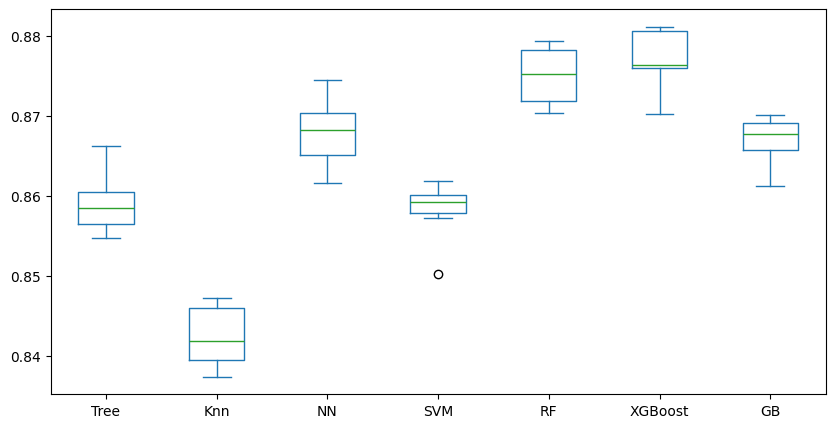

In [28]:
#Resultados de la validación cruzada
comparacion_CV.plot(kind='box', figsize=(10, 5))

In [29]:
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Obtener los modelos presentes en el DataFrame de comparación
modelos_disponibles = list(comparacion_CV.columns)
print(f"Modelos a evaluar: {modelos_disponibles}")

if len(modelos_disponibles) >= 2:
    # Preparar datos de validación cruzada para cada modelo
    datos_anova = [comparacion_CV[modelo] for modelo in modelos_disponibles]

    # 1. Prueba de ANOVA de una vía
    f_val, p_val = stats.f_oneway(*datos_anova)
    print("\n=== PRUEBA DE ANOVA ===")
    print(f"Estadístico F: {f_val:.4f}")
    print(f"Valor p: {p_val:.4e}")

    if p_val < 0.05:
        print("\nResultado: Existen diferencias estadísticamente significativas entre los modelos (p < 0.05).")

        # Reestructurar datos para Tukey
        df_melt = comparacion_CV[modelos_disponibles].melt(var_name='Modelo', value_name='F1_Macro')

        # 2. Prueba Post-Hoc de Tukey HSD
        tukey = pairwise_tukeyhsd(endog=df_melt['F1_Macro'],
                                  groups=df_melt['Modelo'],
                                  alpha=0.05)
        print("\n=== PRUEBA POST-HOC DE TUKEY HSD ===")
        print(tukey.summary())
    else:
        print("\nResultado: No se encontraron diferencias estadísticamente significativas entre los modelos (p >= 0.05).")
else:
    print("\nError: Se necesitan al menos 2 modelos en 'comparacion_CV' para poder realizar la comparación.")

Modelos a evaluar: ['Tree', 'Knn', 'NN', 'SVM', 'RF', 'XGBoost', 'GB']

=== PRUEBA DE ANOVA ===
Estadístico F: 116.5712
Valor p: 3.5758e-32

Resultado: Existen diferencias estadísticamente significativas entre los modelos (p < 0.05).

=== PRUEBA POST-HOC DE TUKEY HSD ===
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1  group2 meandiff p-adj   lower   upper  reject
-----------------------------------------------------
    GB     Knn  -0.0247    0.0 -0.0294   -0.02   True
    GB      NN   0.0008 0.9989  -0.004  0.0055  False
    GB      RF   0.0078 0.0001  0.0031  0.0125   True
    GB     SVM  -0.0087    0.0 -0.0134 -0.0039   True
    GB    Tree  -0.0084    0.0 -0.0131 -0.0037   True
    GB XGBoost   0.0099    0.0  0.0052  0.0146   True
   Knn      NN   0.0255    0.0  0.0208  0.0302   True
   Knn      RF   0.0325    0.0  0.0278  0.0372   True
   Knn     SVM   0.0161    0.0  0.0114  0.0208   True
   Knn    Tree   0.0163    0.0  0.0116   0.021   True
   Knn XGBoost   0.0346   

In [30]:
#Los 3 mejores modelos según el F1 macro promedio
comparacion_CV.mean().sort_values(ascending=False)

XGBoost    0.877068
RF         0.874938
NN         0.867901
GB         0.867138
Tree       0.858745
SVM        0.858488
Knn        0.842418
dtype: float64

GridSearch a los 3 mejores modelos


In [31]:
#Configuración hiperparametrización
from sklearn.model_selection import GridSearchCV
scoring = 'f1_macro' #Se usan los mismos 10 pliegues (cv) de la validación cruzada

#Medida de evaluación de los modelos ajustados
medidas = pd.DataFrame(index=['f1 de la CV'])

GridSearch Random Forest


In [32]:
#Hiperparametrización Random Forest con GridSearch
modelRF = RandomForestClassifier(max_samples=0.9, random_state=42, n_jobs=-1)

# Definir los hiperparametros
n_estimators = [100, 200, 300] #Cantidad de árboles
max_depth = [8, 10, 12, 15, 20] #Niveles de profundidad
min_samples_leaf = [2, 5, 10, 20] #Cantidad de registros por hoja

#Grid
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
grid = GridSearchCV(estimator=modelRF, param_grid=param_grid, scoring=scoring, cv=cv, return_train_score=True, refit=True)
grid.fit(X, Y)

#Mejor modelo
modelRF_grid = grid.best_estimator_

# Mejores párametros
print(grid.best_params_)

{'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 200}


In [33]:
#Revisar overfitting y underfitting
print("Train CV:", grid.cv_results_["mean_train_score"][grid.best_index_])
print("Test CV:", grid.cv_results_["mean_test_score"][grid.best_index_])

#Medida de evaluación del mejor modelo
medidas['RF GridSearch'] = grid.best_score_
medidas

Train CV: 0.8841812308363
Test CV: 0.8749384159600229


,RF GridSearch
f1 de la CV,0.874938


gridSearch XGBoost



In [34]:
#Hiperparametrización XGBoost con GridSearch
modelXGB = XGBClassifier(random_state=42, n_jobs=-1)

# Definir los hiperparametros
n_estimators = [200, 300, 400] #Cantidad de árboles
max_depth = [4, 6, 8] #Niveles de profundidad
learning_rate = [0.05, 0.1] #Tasa de aprendizaje

#Grid
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
grid = GridSearchCV(estimator=modelXGB, param_grid=param_grid, scoring=scoring, cv=cv, return_train_score=True, refit=True)
grid.fit(X, Y)

#Mejor modelo
modelXGB_grid = grid.best_estimator_

# Mejores párametros
print(grid.best_params_)

{'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 400}


In [35]:
#Revisar overfitting y underfitting
print("Train CV:", grid.cv_results_["mean_train_score"][grid.best_index_])
print("Test CV:", grid.cv_results_["mean_test_score"][grid.best_index_])

#Medida de evaluación del mejor modelo
medidas['XGBoost GridSearch'] = grid.best_score_
medidas

Train CV: 0.9055759380102704
Test CV: 0.8833340526101155


,RF GridSearch,XGBoost GridSearch
f1 de la CV,0.874938,0.883334


GrindSearch Gradient Boosting


In [36]:
#Hiperparametrización Gradient Boosting con GridSearch
modelGB = GradientBoostingClassifier(random_state=42)

# Definir los hiperparametros
n_estimators = [100, 200, 300] #Cantidad de árboles
max_depth = [3, 4, 5] #Niveles de profundidad
learning_rate = [0.05, 0.1] #Tasa de aprendizaje

#Grid
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
grid = GridSearchCV(estimator=modelGB, param_grid=param_grid, scoring=scoring, cv=cv, return_train_score=True, refit=True)
grid.fit(X, Y)

#Mejor modelo
modelGB_grid = grid.best_estimator_

# Mejores párametros
print(grid.best_params_)

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}


In [37]:
#Revisar overfitting y underfitting
print("Train CV:", grid.cv_results_["mean_train_score"][grid.best_index_])
print("Test CV:", grid.cv_results_["mean_test_score"][grid.best_index_])

#Medida de evaluación del mejor modelo
medidas['GB GridSearch'] = grid.best_score_
medidas

Train CV: 0.8825795015880082
Test CV: 0.8750476690512479


,RF GridSearch,XGBoost GridSearch,GB GridSearch
f1 de la CV,0.874938,0.883334,0.875048


In [38]:
!pip install -q scikit-optimize


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


optimizacion bayesiana


In [39]:
#Optimización bayesiana
from skopt import BayesSearchCV

#Hiperparametrización Random Forest con optimización bayesiana
modelRF = RandomForestClassifier(max_samples=0.9, random_state=42, n_jobs=-1)

# Definir los rangos de los hiperparametros (mínimo, máximo)
n_estimators = (100, 500)
max_depth = (5, 20)
min_samples_leaf = (2, 30)

#Bayesiana (20 intentos)
espacio = dict(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
bayes = BayesSearchCV(estimator=modelRF, search_spaces=espacio, n_iter=20, scoring=scoring, cv=cv, return_train_score=True, refit=True, random_state=42)
bayes.fit(X, Y)

#Mejor modelo
modelRF_bayes = bayes.best_estimator_

# Mejores párametros
print(dict(bayes.best_params_))

{'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 500}


In [40]:
#Revisar overfitting y underfitting
print("Train CV:", bayes.cv_results_["mean_train_score"][bayes.best_index_])
print("Test CV:", bayes.cv_results_["mean_test_score"][bayes.best_index_])

#Medida de evaluación del mejor modelo
medidas['RF Bayesiana'] = bayes.best_score_
medidas

Train CV: 0.8840999196240921
Test CV: 0.8748211345657012


,RF GridSearch,XGBoost GridSearch,GB GridSearch,RF Bayesiana
f1 de la CV,0.874938,0.883334,0.875048,0.874821


In [41]:
#Hiperparametrización XGBoost con optimización bayesiana
modelXGB = XGBClassifier(random_state=42, n_jobs=-1)

# Definir los rangos de los hiperparametros (mínimo, máximo)
n_estimators = (100, 600)
max_depth = (3, 7)
learning_rate = (0.01, 0.3, 'log-uniform')

#Bayesiana (20 intentos)
espacio = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
bayes = BayesSearchCV(estimator=modelXGB, search_spaces=espacio, n_iter=20, scoring=scoring, cv=cv, return_train_score=True, refit=True, random_state=42)
bayes.fit(X, Y)

#Mejor modelo
modelXGB_bayes = bayes.best_estimator_

# Mejores párametros
print(dict(bayes.best_params_))

{'learning_rate': 0.17396068310086973, 'max_depth': 7, 'n_estimators': 482}


In [42]:
#Revisar overfitting y underfitting
print("Train CV:", bayes.cv_results_["mean_train_score"][bayes.best_index_])
print("Test CV:", bayes.cv_results_["mean_test_score"][bayes.best_index_])

#Medida de evaluación del mejor modelo
medidas['XGBoost Bayesiana'] = bayes.best_score_
medidas

Train CV: 0.9146891940748386
Test CV: 0.8843859781929151


,RF GridSearch,XGBoost GridSearch,GB GridSearch,RF Bayesiana,XGBoost Bayesiana
f1 de la CV,0.874938,0.883334,0.875048,0.874821,0.884386


In [43]:
#Hiperparametrización Gradient Boosting con optimización bayesiana
modelGB = GradientBoostingClassifier(random_state=42)

# Definir los rangos de los hiperparametros (mínimo, máximo)
n_estimators = (100, 400)
max_depth = (2, 6)
learning_rate = (0.01, 0.3, 'log-uniform')

#Bayesiana (20 intentos)
espacio = dict(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate)
bayes = BayesSearchCV(estimator=modelGB, search_spaces=espacio, n_iter=20, scoring=scoring, cv=cv, return_train_score=True, refit=True, random_state=42)
bayes.fit(X, Y)

#Mejor modelo
modelGB_bayes = bayes.best_estimator_

# Mejores párametros
print(dict(bayes.best_params_))

{'learning_rate': 0.21116719970114348, 'max_depth': 6, 'n_estimators': 400}


In [44]:
#Revisar overfitting y underfitting
print("Train CV:", bayes.cv_results_["mean_train_score"][bayes.best_index_])
print("Test CV:", bayes.cv_results_["mean_test_score"][bayes.best_index_])

#Medida de evaluación del mejor modelo
medidas['GB Bayesiana'] = bayes.best_score_
medidas

Train CV: 0.9231350702226468
Test CV: 0.8826799339621745


,RF GridSearch,XGBoost GridSearch,GB GridSearch,RF Bayesiana,XGBoost Bayesiana,GB Bayesiana
f1 de la CV,0.874938,0.883334,0.875048,0.874821,0.884386,0.88268


seleccion mejor modelo


In [45]:
medidas.T.sort_values('f1 de la CV', ascending=False)

,f1 de la CV
XGBoost Bayesiana,0.884386
XGBoost GridSearch,0.883334
GB Bayesiana,0.882680
GB GridSearch,0.875048
RF GridSearch,0.874938
RF Bayesiana,0.874821


In [46]:
#Mejor modelo: mayor f1 de la CV con diferencia train-test menor a 5 puntos (sin overfitting)
modelo_final = modelXGB_bayes
print(type(modelo_final).__name__, {p: modelo_final.get_params()[p] for p in ['n_estimators', 'max_depth', 'learning_rate']})

XGBClassifier {'n_estimators': 482, 'max_depth': 7, 'learning_rate': 0.17396068310086973}


Pipe del modelo final


In [47]:
#Pipe con las operaciones de preparación de los datos y el mejor modelo
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.base import clone

otras_categoricas = [variable for variable in categoricas if variable != 'country']
preparacion = ColumnTransformer([
    ('numericas', MinMaxScaler(), predictoras_numericas), #Normalización
    ('paises', OneHotEncoder(categories=[sorted(paises)], handle_unknown='ignore', sparse_output=False, dtype=int), ['country']), #Dummies de los 20 países
    ('otros', FunctionTransformer(np.isin, kw_args={'test_elements': paises, 'invert': True}, feature_names_out='one-to-one'), ['country']), #Dummy "Otros": países fuera de los 20
    ('categoricas', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False, dtype=int), otras_categoricas)]) #Dummies (2 categorías: drop first)

pipe = Pipeline([('preparacion', preparacion), ('modelo', clone(modelo_final))])
pipe.fit(X_smote, y_smote) #Modelo final con el 70% balanceado (antes de dummies y normalización)

Pipeline(steps=[('preparacion',
                 ColumnTransformer(transformers=[('numericas', MinMaxScaler(),
                                                  ['lead_time', 'adults',
                                                   'previous_cancellations',
                                                   'previous_bookings_not_canceled',
                                                   'booking_changes',
                                                   'days_in_waiting_list',
                                                   'required_car_parking_spaces',
                                                   'total_of_special_requests']),
                                                 ('paises',
                                                  OneHotEncoder(categories=[['AUT',
                                                                             'BEL',
                                                                             'BRA',
                                                                             'CHE',
                                                                             'CHN',
                                                                             'CN',
                                                                             'DEU',...
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.17396068310086973, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=7,
                               max_leaves=None, min_child_weight=None,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=482, n_jobs=-1,
                               num_parallel_tree=None, ...))])

Evaluación con el 30%


In [48]:
#Evaluación del modelo final con el 30% (datos reales sin balancear)
from sklearn import metrics
Y_pred = pipe.predict(X_test) #El Pipe aplica la preparación a los datos originales

medidas_test = pd.DataFrame(index=['f1_macro', 'accuracy', 'precision_macro', 'recall_macro'])
medidas_test['Test 30%'] = [metrics.f1_score(Y_test, Y_pred, average='macro'), metrics.accuracy_score(Y_test, Y_pred),
                            metrics.precision_score(Y_test, Y_pred, average='macro'), metrics.recall_score(Y_test, Y_pred, average='macro')]
medidas_test

,Test 30%
f1_macro,0.846168
accuracy,0.858793
precision_macro,0.853072
recall_macro,0.840926


In [49]:
#Medidas por clase (0: no cancelada, 1: cancelada)
print(metrics.classification_report(Y_test, Y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.8713    0.9101    0.8902     22503
           1     0.8349    0.7718    0.8021     13260

    accuracy                         0.8588     35763
   macro avg     0.8531    0.8409    0.8462     35763
weighted avg     0.8578    0.8588    0.8576     35763



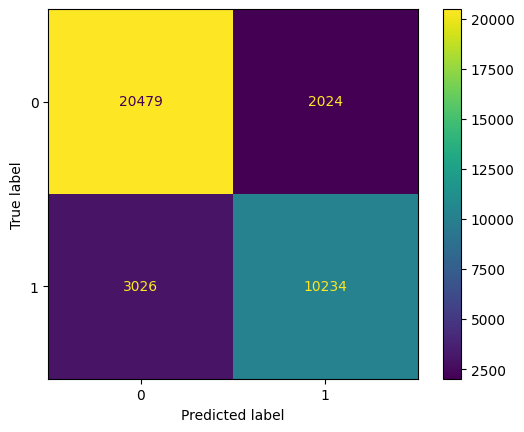

In [53]:
#Matriz de confusión del 30%
metrics.ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred, values_format='d')

Guardar el Pipe para el despliegue


In [54]:
#Se guarda el Pipe para el despliegue
import pickle
filename = 'modelo_hotel_bookings.pkl'
pickle.dump(pipe, open(filename, 'wb'))

In [55]:
#Prueba del Pipe guardado con datos nuevos (5 reservas del 30%)
pipe_cargado = pickle.load(open(filename, 'rb'))
prueba = X_test.head().copy()
prueba['Predicción'] = pipe_cargado.predict(X_test.head())
prueba['Probabilidad de cancelación'] = pipe_cargado.predict_proba(X_test.head())[:, 1].round(4)
prueba['is_canceled (real)'] = Y_test.head().values
prueba

,hotel,lead_time,arrival_date_month,adults,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,required_car_parking_spaces,total_of_special_requests,Predicción,Probabilidad de cancelación,is_canceled (real)
55070,City Hotel,41,August,2,BRA,Direct,Direct,0,0,0,E,0,No Deposit,0,Transient,0,0,1,0.5736,1
34729,Resort Hotel,32,March,2,GBR,Offline TA/TO,TA/TO,0,0,0,D,0,No Deposit,0,Transient,0,0,0,0.0027,0
80615,City Hotel,32,November,1,PRT,Offline TA/TO,TA/TO,0,0,0,A,0,No Deposit,0,Transient-Party,0,0,0,0.1296,0
94704,City Hotel,4,August,2,PRT,Online TA,TA/TO,0,0,0,A,0,No Deposit,0,Transient,1,2,0,0.0001,0
39514,Resort Hotel,0,August,2,PRT,Direct,Direct,1,0,0,E,0,No Deposit,0,Transient,1,1,0,0.0000,0
